In [10]:
import spatialdata as sd      # opens the .zarr
import scanpy as sc           # QC and filtering
import squidpy as sq          # the tissue plot
import pandas as pd           # the binning and tables
import matplotlib.pyplot as plt
import seaborn as sns         # histograms
import numpy as np
import os

In [2]:
zarr_path = "/nobackup/proj/comet_smmnfst/xenium_data/Region_1_20260827.zarr"
out_dir   = "/nobackup/proj/comet_smmnfst/processed/"

sdata = sd.read_zarr(zarr_path)
adata = sdata.tables["table"].copy()

no parent found for <ome_zarr.reader.Label object at 0x7ff76411eae0>: None
no parent found for <ome_zarr.reader.Label object at 0x7ff76414eb70>: None


In [7]:
y = adata.obsm["spatial"][:, 1]

In [8]:
ys = np.sort(y)
gaps = np.diff(ys)
edges = ys[np.argsort(gaps)[-2:]]           # the two biggest jumps
edges = np.sort(edges)
print(edges)
adata.obs["section"] = pd.cut(y, bins=[y.min()-1, *edges, y.max()+1], labels=["S1", "S2", "S3"])

[2069.91748047 4340.23339844]


section
S2    10790
S1    10764
S3    10433
Name: count, dtype: int64


/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


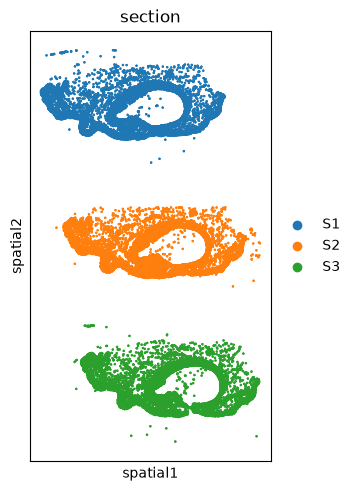

In [9]:
print(adata.obs["section"].value_counts())
sq.pl.spatial_scatter(adata, color="section", shape=None, size=2)

In [11]:
os.makedirs(out_dir, exist_ok=True)
adata.write(out_dir + "region1_all_sections_raw.h5ad")

for s in ["S1", "S2", "S3"]:
    sub = adata[adata.obs["section"] == s].copy()
    sub.write(out_dir + f"region1_{s}_raw.h5ad")
    print(s, sub.n_obs, "cells saved")




S1 10764 cells saved
S2 10790 cells saved
S3 10433 cells saved
